# Week 3 Assignment: Matplotlib & Seaborn
**Course:** CDB601220 · **Student:** Sajid Ali · **Data:** Synthetic course datasets

This notebook addresses Parts A–E. It rebuilds the nine claims, tests the proposed explanations against the supplied columns, calculates Lie Factors with `vizlib`, audits palettes under simulated colour-vision deficiency, and creates the clinical 2×2 review figure.

**Reproducibility:** Run from the repository root or from `week3/assignments`. The paths below are resolved relative to this notebook or the repository. All datasets are synthetic; conclusions apply only to these teaching examples.

## Part A : Rebuild and diagnose the nine claims
Each case first reproduces the specified chart/table, then checks the explanation using available context columns and shows a more defensible alternative.

,injuries,trips,injuries_per_1000_trips
helmet_grade,,,
Premium,216,40000,5.40
Standard,129,60000,2.15


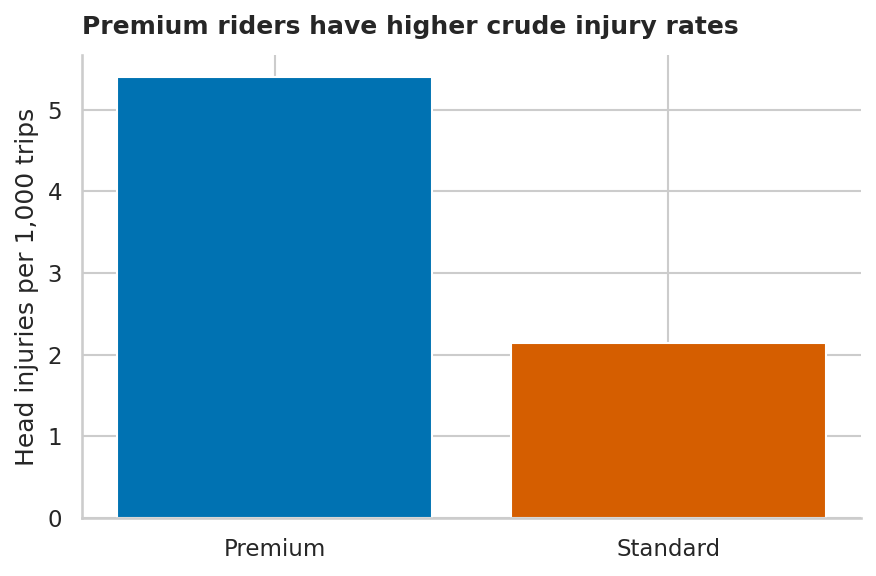

injuries  trips  rate_per_1000
helmet_grade road_type                                       
Premium      City arterial           11   5000           2.20
             Inner-city lanes         1   1000           1.00
             Motorway               204  34000           6.00
Standard     City arterial           60  20000           3.00
             Inner-city lanes        53  38000           1.39
             Motorway                16   2000           8.00

Mean rider speed by helmet grade:


helmet_grade
Premium     66.95
Standard    30.22
Name: mean_speed_kph, dtype: float64

Diagnosis: the crude contrast is confounded by road-type exposure. Premium riders completed 34,000/40,000 trips on motorways; Standard riders completed only 2,000/60,000 there. Motorway injury rates are high for both groups. The data do not establish a causal helmet effect.


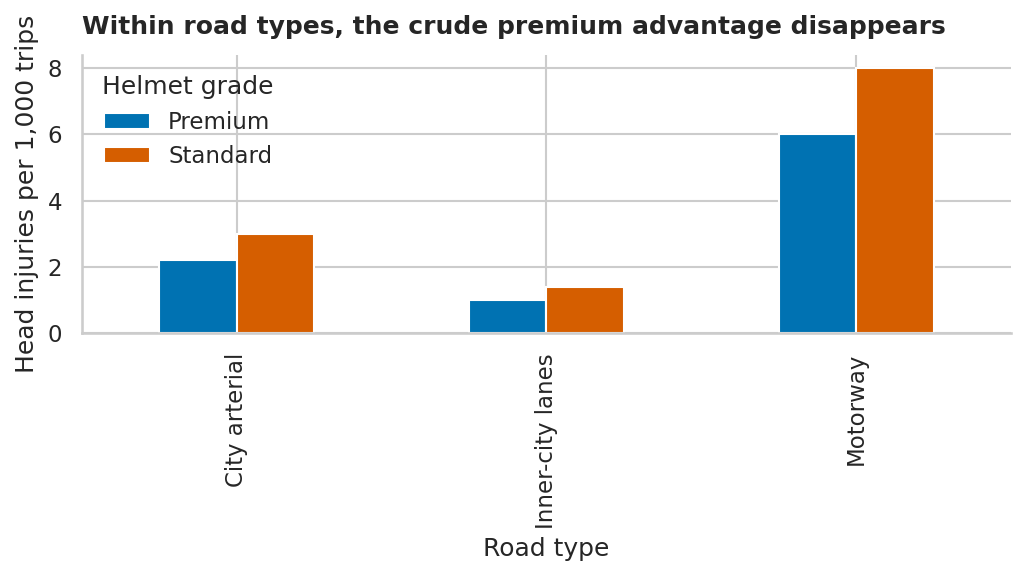

In [ ]:
# A1. Helmet grade and head injuries
helmet = pd.read_csv(DATA / "case01_helmet_rickshaw.csv")
helmet_summary = helmet.groupby("helmet_grade").agg(
    injuries=("head_injuries", "sum"), trips=("trips", "sum"))
helmet_summary["injuries_per_1000_trips"] = 1000 * helmet_summary.injuries / helmet_summary.trips
display(helmet_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(helmet_summary.index, helmet_summary.injuries_per_1000_trips,
       color=[PALETTE["series"][0], PALETTE["series"][1]])
ax.set_ylim(0, None)
ax.set_ylabel("Head injuries per 1,000 trips")
ax.set_title("Premium riders have higher crude injury rates")
fig.tight_layout()
plt.show()

# Mechanism test: exposure to road types differs dramatically by helmet grade.
road = helmet.groupby(["helmet_grade", "road_type"]).agg(
    injuries=("head_injuries", "sum"), trips=("trips", "sum"))
road["rate_per_1000"] = 1000 * road.injuries / road.trips
display(road.round(2))
print("Mean rider speed by helmet grade:")
display(helmet.groupby("helmet_grade").avg_speed_kph.mean().rename("mean_speed_kph").round(2))
print("Diagnosis: the crude contrast is confounded by road-type exposure. Premium riders completed 34,000/40,000 trips on motorways; Standard riders completed only 2,000/60,000 there. Motorway injury rates are high for both groups. The data do not establish a causal helmet effect.")
fig, ax = plt.subplots(figsize=(7, 4))
rates = road["rate_per_1000"].unstack("helmet_grade")
rates.plot(kind="bar", ax=ax, color=[PALETTE["series"][0], PALETTE["series"][1]])
ax.set_ylabel("Head injuries per 1,000 trips")
ax.set_xlabel("Road type")
ax.set_title("Within road types, the crude premium advantage disappears")
ax.legend(title="Helmet grade")
fig.tight_layout()
plt.show()

Pearson r = 0.982; students enrolled vs chai sales r = 0.997


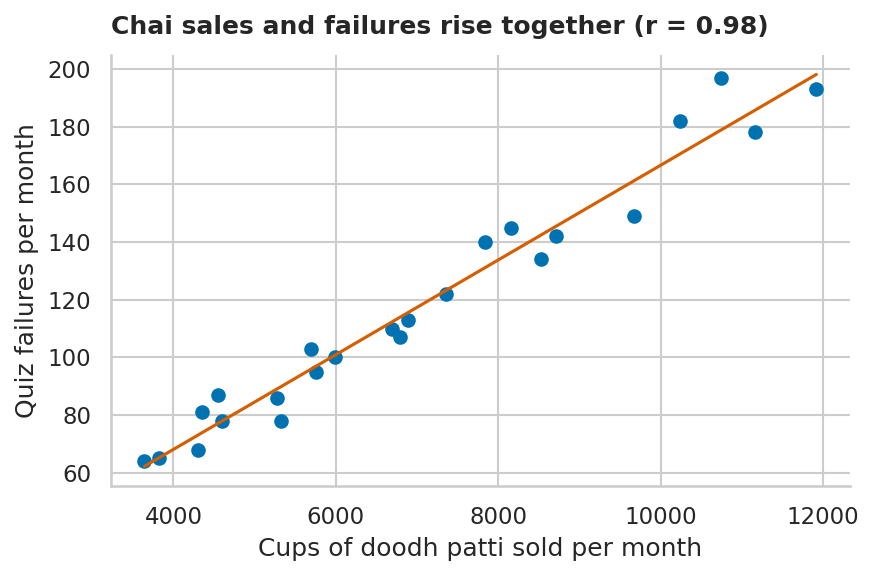

Diagnosis: monthly totals share scale with enrollment; enrollment correlates with chai sales at r = 0.997 and with failures at r = 0.977 . Exam timing is a separate context variable, not evidence that chai causes failures.


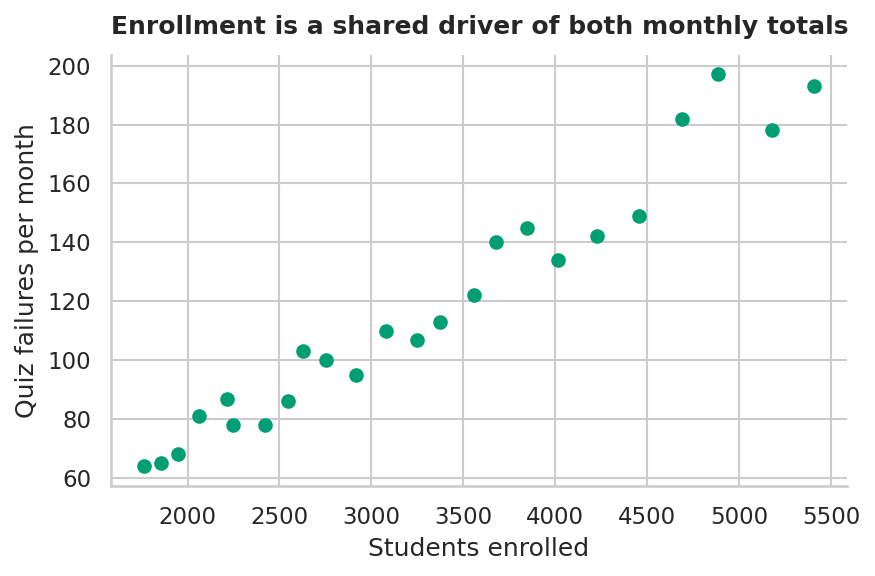

In [ ]:
# A2. Chai sales and quiz failures
chai = pd.read_csv(DATA / "case02_chai_quizzes.csv")
r = chai["cups_doodh_patti_sold"].corr(chai["quiz_failures"])
slope, intercept, *_ = stats.linregress(chai["cups_doodh_patti_sold"], chai["quiz_failures"])
print(f"Pearson r = {r:.3f}; students enrolled vs chai sales r = {chai.students_enrolled.corr(chai.cups_doodh_patti_sold):.3f}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(chai.cups_doodh_patti_sold, chai.quiz_failures, color=PALETTE["series"][0])
xx = np.linspace(chai.cups_doodh_patti_sold.min(), chai.cups_doodh_patti_sold.max(), 100)
ax.plot(xx, slope*xx+intercept, color=PALETTE["series"][1])
ax.set_xlabel("Cups of doodh patti sold per month")
ax.set_ylabel("Quiz failures per month")
ax.set_title(f"Chai sales and failures rise together (r = {r:.2f})")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(chai.students_enrolled, chai.quiz_failures, color=PALETTE["series"][2])
ax.set_xlabel("Students enrolled")
ax.set_ylabel("Quiz failures per month")
ax.set_title("Enrollment is a shared driver of both monthly totals")
print("Diagnosis: monthly totals share scale with enrollment; enrollment correlates with chai sales at r =", round(chai.students_enrolled.corr(chai.cups_doodh_patti_sold),3), "and with failures at r =", round(chai.students_enrolled.corr(chai.quiz_failures),3), ". Exam timing is a separate context variable, not evidence that chai causes failures.")
fig.tight_layout()
plt.show()

Rebuilt self-check: before=202.1, after=137.2, change=-32.1%


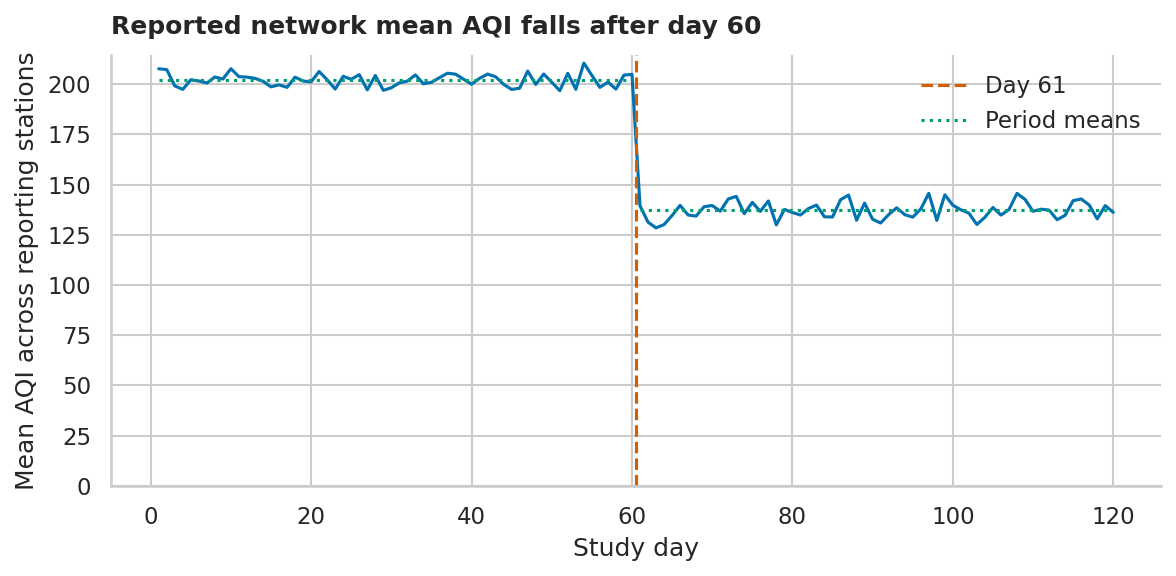

,mean_aqi,mean_reporting_stations
day,,
Days 1–60,202.094621,22.0
Days 61–120,137.205769,13.0


Diagnosis: this aggregation averages whichever stations reported on each date. Check reporting coverage and station/zone composition before attributing the decline to a policy; blank AQI is missing, not zero.


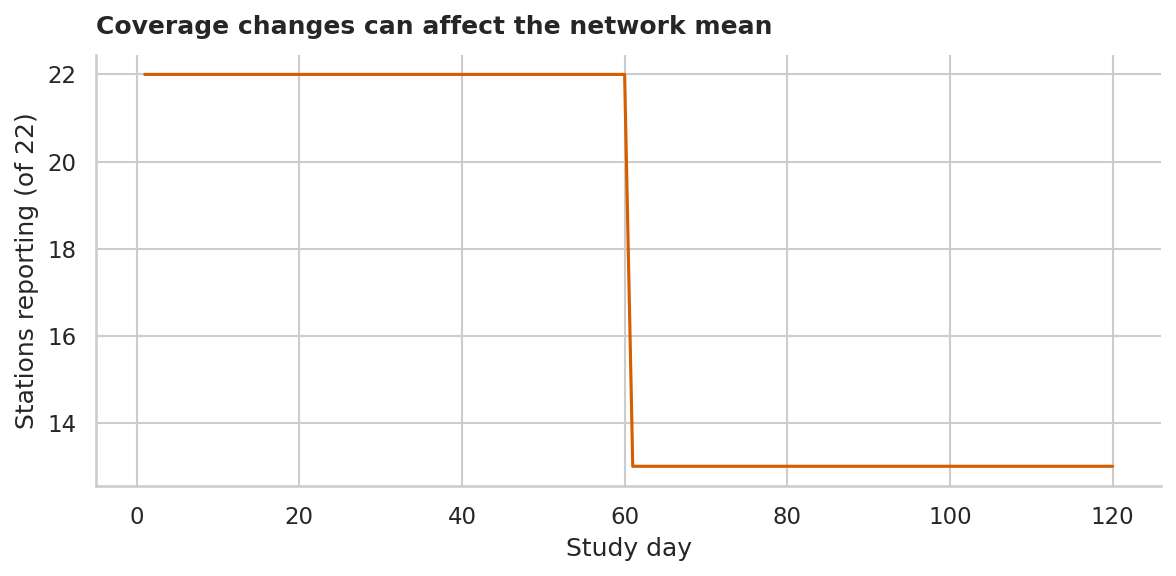

In [ ]:
# A3. AQI before/after day 61
aqi = pd.read_csv(DATA / "case03_aqi_monitors.csv", parse_dates=["date"])
daily = aqi.groupby("date", as_index=False).agg(mean_aqi=("aqi", "mean"), reporting_stations=("aqi", "count"))
daily["day"] = np.arange(1, len(daily)+1)
before = daily.loc[daily.day <= 60, "mean_aqi"].mean()
after = daily.loc[daily.day >= 61, "mean_aqi"].mean()
print(f"Rebuilt self-check: before={before:.1f}, after={after:.1f}, change={(after-before)/before:.1%}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily.day, daily.mean_aqi, color=PALETTE["series"][0])
ax.axvline(60.5, color=PALETTE["series"][1], linestyle="--", label="Day 61")
ax.hlines(before, 1, 60, color=PALETTE["series"][2], linestyle=":")
ax.hlines(after, 61, 120, color=PALETTE["series"][2], linestyle=":", label="Period means")
ax.set_ylim(0, None)
ax.set_xlabel("Study day")
ax.set_ylabel("Mean AQI across reporting stations")
ax.set_title("Reported network mean AQI falls after day 60")
ax.legend()
fig.tight_layout()
plt.show()
display(daily.groupby(daily.day.le(60).map({True:"Days 1–60",False:"Days 61–120"})).agg(mean_aqi=("mean_aqi","mean"), mean_reporting_stations=("reporting_stations","mean")))
print("Diagnosis: this aggregation averages whichever stations reported on each date. Check reporting coverage and station/zone composition before attributing the decline to a policy; blank AQI is missing, not zero.")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily.day, daily.reporting_stations, color=PALETTE["series"][1])
ax.set_xlabel("Study day"); ax.set_ylabel("Stations reporting (of 22)")
ax.set_title("Coverage changes can affect the network mean")
fig.tight_layout(); plt.show()

,n,mean_x,mean_y,sd_x,sd_y,pearson_r,slope
department,,,,,,,
Architecture,11,18.0,14.501,6.325,1.936,0.817,0.25
Business Administration,11,18.0,14.501,6.325,1.937,0.816,0.25
Computer Science,11,18.0,14.501,6.325,1.937,0.816,0.25
Electrical Engineering,11,18.0,14.500,6.325,1.936,0.816,0.25


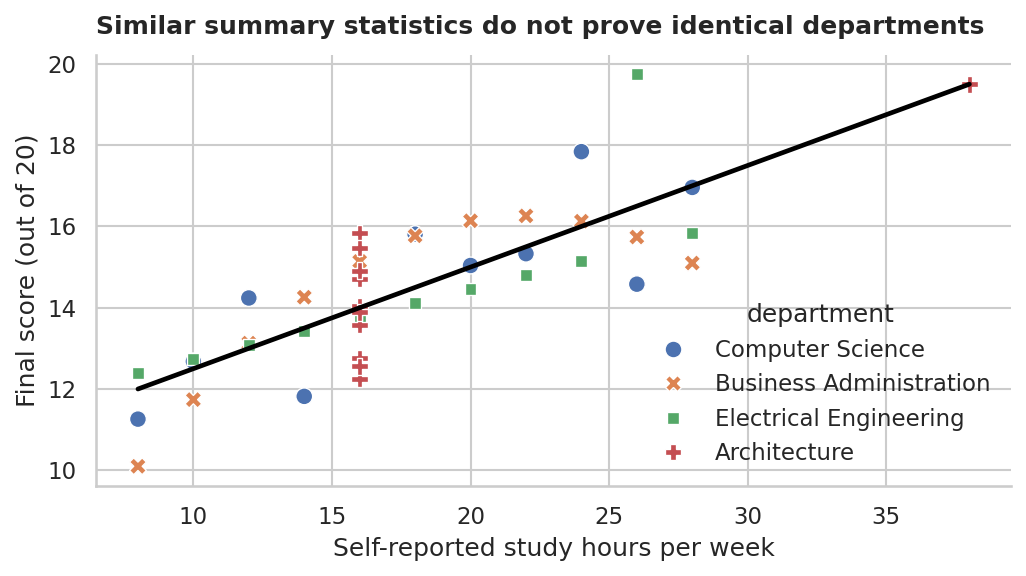

Diagnosis: matching means and correlations conceal different point patterns and influential observations; inspect the scatter, not only the summaries.


In [ ]:
# A4. Department quartet: summary statistics and correlations
quartet = pd.read_csv(DATA / "case04_quartet_depts.csv")
def summary_table(df, group, x, y):
    rows = []
    for name, g in df.groupby(group, sort=True):
        rows.append({
            group: name, "n": len(g), "mean_x": g[x].mean(), "mean_y": g[y].mean(),
            "sd_x": g[x].std(ddof=0), "sd_y": g[y].std(ddof=0),
            "pearson_r": g[x].corr(g[y]),
            "slope": np.polyfit(g[x], g[y], 1)[0] if g[x].nunique()>1 else np.nan
        })
    return pd.DataFrame(rows).set_index(group)
display(summary_table(quartet, "department", "study_hours_per_week", "final_score_out_of_20").round(3))
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=quartet, x="study_hours_per_week", y="final_score_out_of_20",
                hue="department", style="department", s=65, ax=ax)
sns.regplot(data=quartet, x="study_hours_per_week", y="final_score_out_of_20",
            scatter=False, ci=None, color="black", ax=ax)
ax.set_title("Similar summary statistics do not prove identical departments")
ax.set_xlabel("Self-reported study hours per week"); ax.set_ylabel("Final score (out of 20)")
fig.tight_layout(); plt.show()
print("Diagnosis: matching means and correlations conceal different point patterns and influential observations; inspect the scatter, not only the summaries.")

,n,mean_x,mean_y,sd_x,sd_y,pearson_r,slope
shape_name,,,,,,,
ring,180,48.0,63.0,12.0,15.0,0.42,0.525
star,180,48.0,63.0,12.0,15.0,0.42,0.525
straight line,180,48.0,63.0,12.0,15.0,0.42,0.525
the letter X,180,48.0,63.0,12.0,15.0,0.42,0.525
two clusters,180,48.0,63.0,12.0,15.0,0.42,0.525


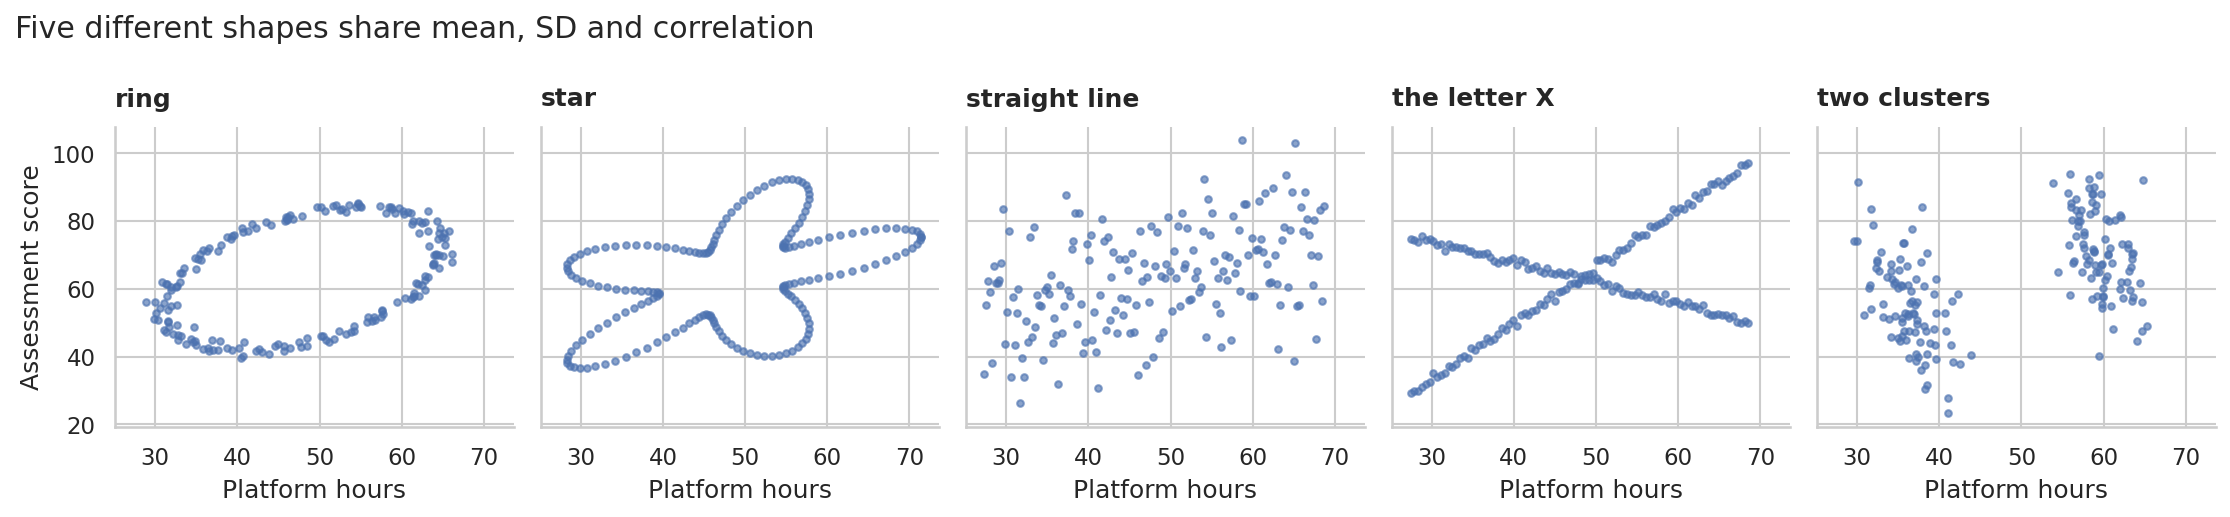

Diagnosis: the matching summaries do not constrain geometry. Different clusters, curves or outliers can have the same mean, SD and Pearson r.


In [ ]:
# A5. Five cohorts with matching statistics but different shapes
shapes = pd.read_csv(DATA / "case05_same_stats_shapes.csv")
display(summary_table(shapes, "shape_name", "hours_on_platform", "assessment_score").round(3))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharex=True, sharey=True)
for ax, (name, g) in zip(axes, shapes.groupby("shape_name", sort=True)):
    ax.scatter(g.hours_on_platform, g.assessment_score, s=10, alpha=.65)
    ax.set_title(name)
    ax.set_xlabel("Platform hours")
axes[0].set_ylabel("Assessment score")
fig.suptitle("Five different shapes share mean, SD and correlation", x=.01, ha="left")
fig.tight_layout(); plt.show()
print("Diagnosis: the matching summaries do not constrain geometry. Different clusters, curves or outliers can have the same mean, SD and Pearson r.")

Matrix shape: (20, 20) | creatinine↔HbA1c: 0.77 | systolic↔MAP: 0.96


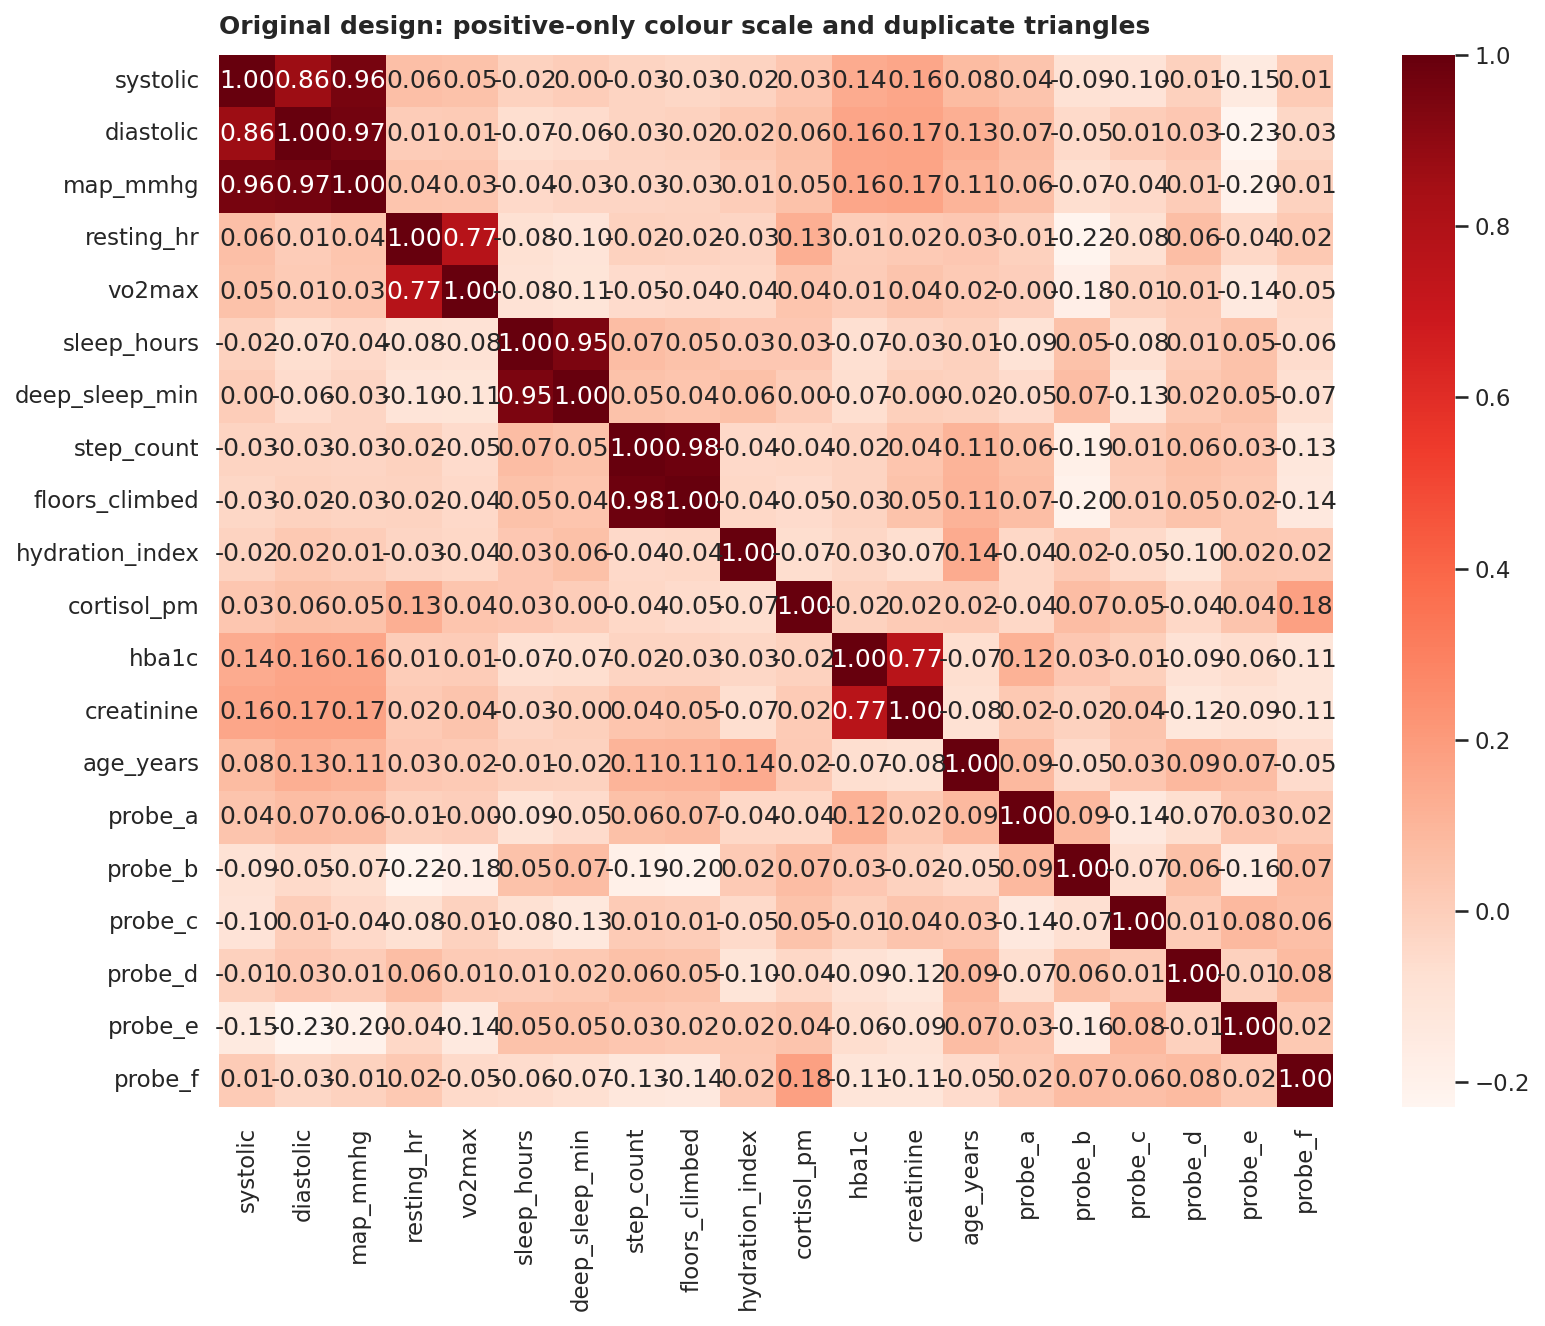

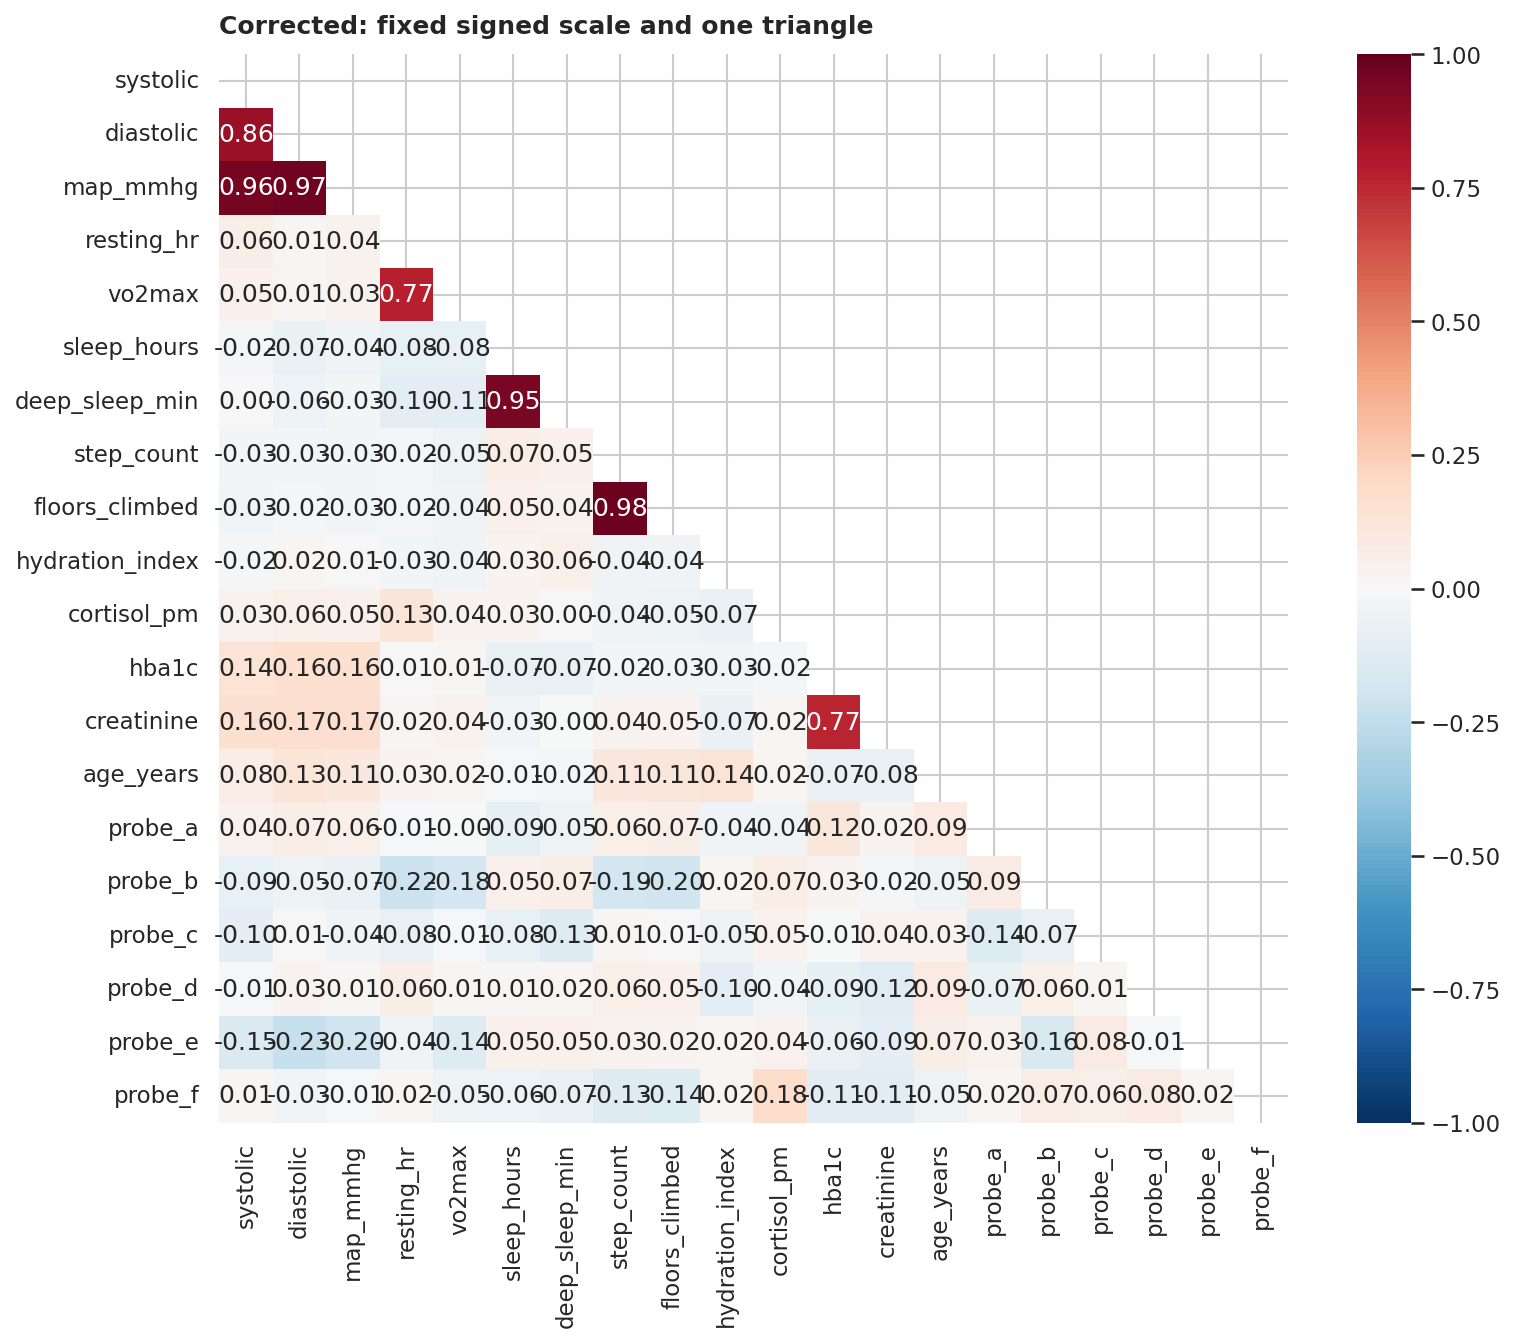

Diagnosis: creatinine–HbA1c correlation is a hypothesis to investigate, not automatically a finding. The systolic–MAP correlation is partly arithmetic because MAP is derived from systolic and diastolic pressure. Red-only automatic scaling hides the sign-comparable scale; showing both triangles duplicates information. Fixing the drawing improves interpretation but does not remove confounding or derived-variable problems.


In [ ]:
# A6. Correlation heatmap, exactly as the analyst drew it, then corrected
sensor = pd.read_csv(DATA / "case06_sensor_matrix.csv")
numeric_cols = sensor.select_dtypes(include=np.number).columns.tolist()
excluded = ["age_band", "study_site", "hr_device_model"]
cols = [c for c in numeric_cols if c not in excluded]
corr = sensor[cols].corr()
print("Matrix shape:", corr.shape, "| creatinine↔HbA1c:", round(corr.loc["creatinine","hba1c"],2),
      "| systolic↔MAP:", round(corr.loc["systolic","map_mmhg"],2))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="Reds", annot=True, fmt=".2f", ax=ax)
ax.set_title("Original design: positive-only colour scale and duplicate triangles")
fig.tight_layout(); plt.show()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Corrected: fixed signed scale and one triangle")
fig.tight_layout(); plt.show()
print("Diagnosis: creatinine–HbA1c correlation is a hypothesis to investigate, not automatically a finding. The systolic–MAP correlation is partly arithmetic because MAP is derived from systolic and diastolic pressure. Red-only automatic scaling hides the sign-comparable scale; showing both triangles duplicates information. Fixing the drawing improves interpretation but does not remove confounding or derived-variable problems.")

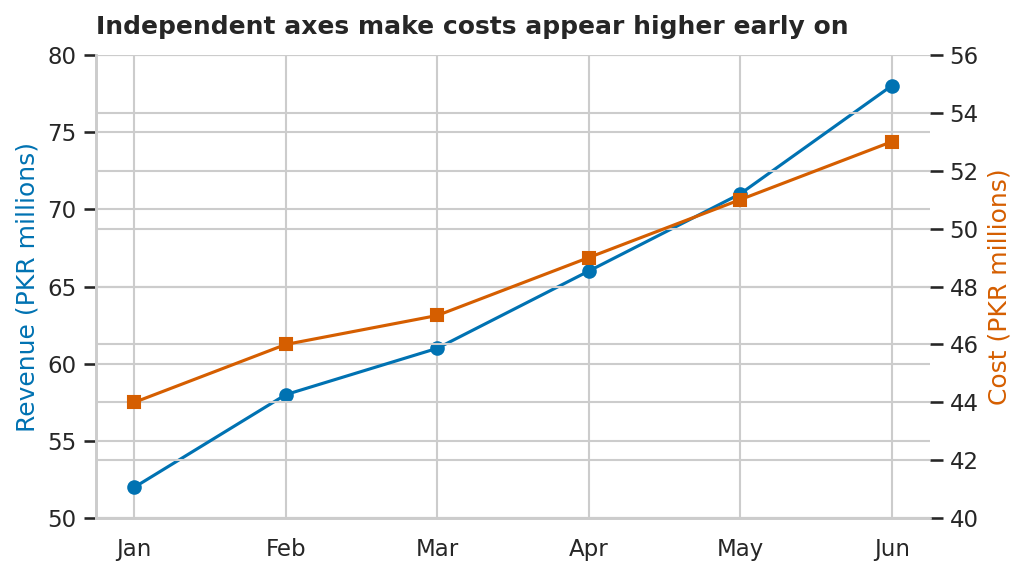

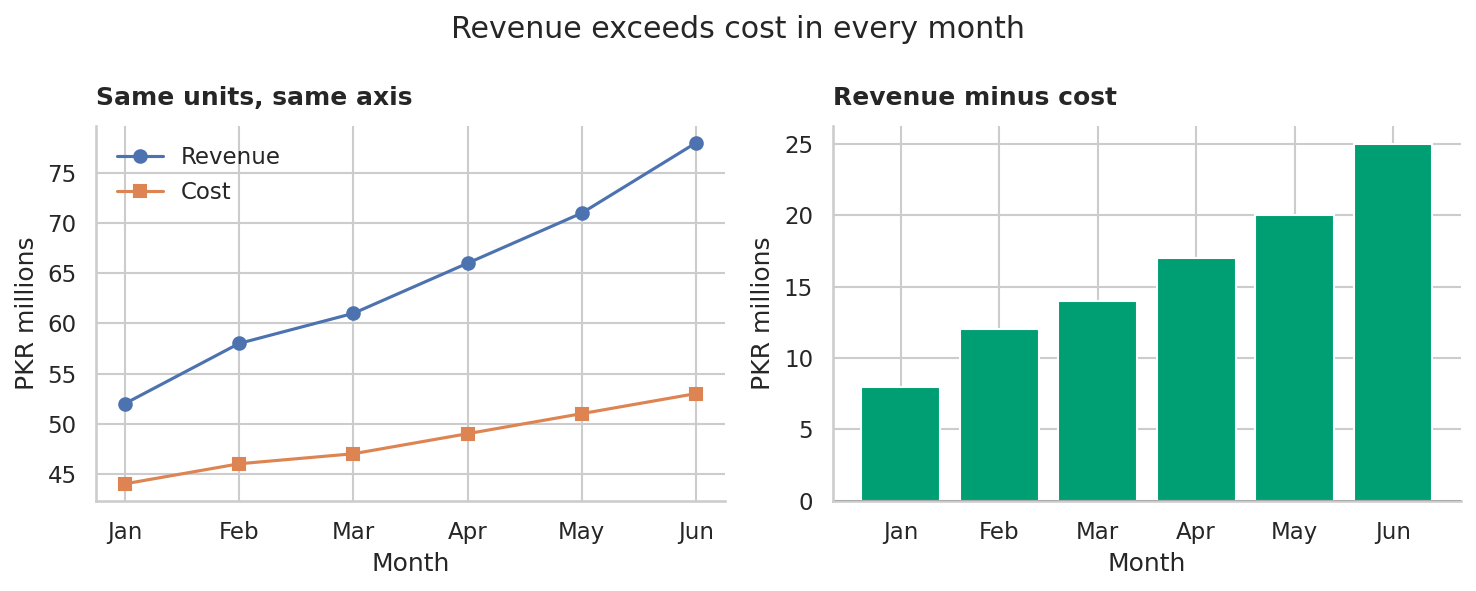

,month,revenue_pkr_m,cost_pkr_m,profit
0,Jan,52,44,8
1,Feb,58,46,12
2,Mar,61,47,14
3,Apr,66,49,17
4,May,71,51,20
5,Jun,78,53,25


Diagnosis: dual axes permit arbitrary visual alignment; the values share units and revenue exceeds cost in every month. A single scale or separate panels reveals the actual comparison.


In [ ]:
# A7. Dual-axis revenue/cost chart and a common-scale redesign
dual = pd.read_csv(DATA / "case07_dual_axis_series.csv")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dual.month, dual.revenue_pkr_m, marker="o", color=PALETTE["series"][0])
ax.set_ylim(50, 80); ax.set_ylabel("Revenue (PKR millions)", color=PALETTE["series"][0])
ax2 = ax.twinx()
ax2.plot(dual.month, dual.cost_pkr_m, marker="s", color=PALETTE["series"][1])
ax2.set_ylim(40, 56); ax2.set_ylabel("Cost (PKR millions)", color=PALETTE["series"][1])
ax.set_title("Independent axes make costs appear higher early on")
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(dual.month, dual.revenue_pkr_m, marker="o", label="Revenue")
axes[0].plot(dual.month, dual.cost_pkr_m, marker="s", label="Cost")
axes[0].set_title("Same units, same axis"); axes[0].set_ylabel("PKR millions"); axes[0].legend()
axes[1].bar(dual.month, dual.revenue_pkr_m-dual.cost_pkr_m, color=PALETTE["series"][2])
axes[1].axhline(0, color="black", linewidth=.8)
axes[1].set_title("Revenue minus cost"); axes[1].set_ylabel("PKR millions")
for a in axes: a.set_xlabel("Month")
fig.suptitle("Revenue exceeds cost in every month")
fig.tight_layout(); plt.show()
display(dual.assign(profit=dual.revenue_pkr_m-dual.cost_pkr_m))
print("Diagnosis: dual axes permit arbitrary visual alignment; the values share units and revenue exceeds cost in every month. A single scale or separate panels reveals the actual comparison.")

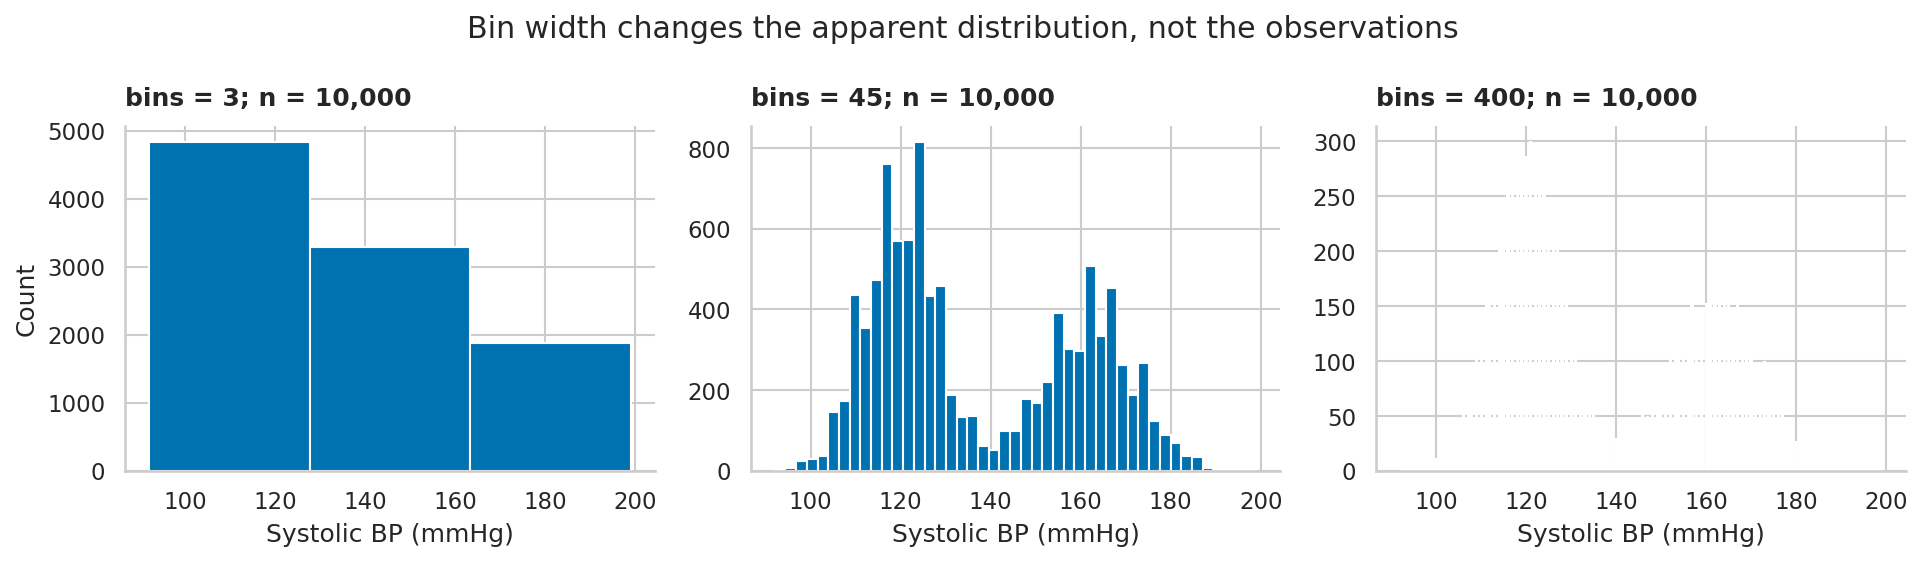

Diagnosis: histogram shape depends strongly on binning. Three bins conceal structure; 400 bins are noisy. Select a defensible binning rule and state it.


In [ ]:
# A8. Three bin widths for systolic blood pressure
vitals_raw = pd.read_csv(DATA / "vitals_10k.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, bins in zip(axes, [3, 45, 400]):
    ax.hist(vitals_raw.systolic, bins=bins, color=PALETTE["series"][0], edgecolor="white")
    ax.set_title(f"bins = {bins}; n = {vitals_raw.systolic.notna().sum():,}")
    ax.set_xlabel("Systolic BP (mmHg)")
axes[0].set_ylabel("Count")
fig.suptitle("Bin width changes the apparent distribution, not the observations")
fig.tight_layout(); plt.show()
print("Diagnosis: histogram shape depends strongly on binning. Three bins conceal structure; 400 bins are noisy. Select a defensible binning rule and state it.")

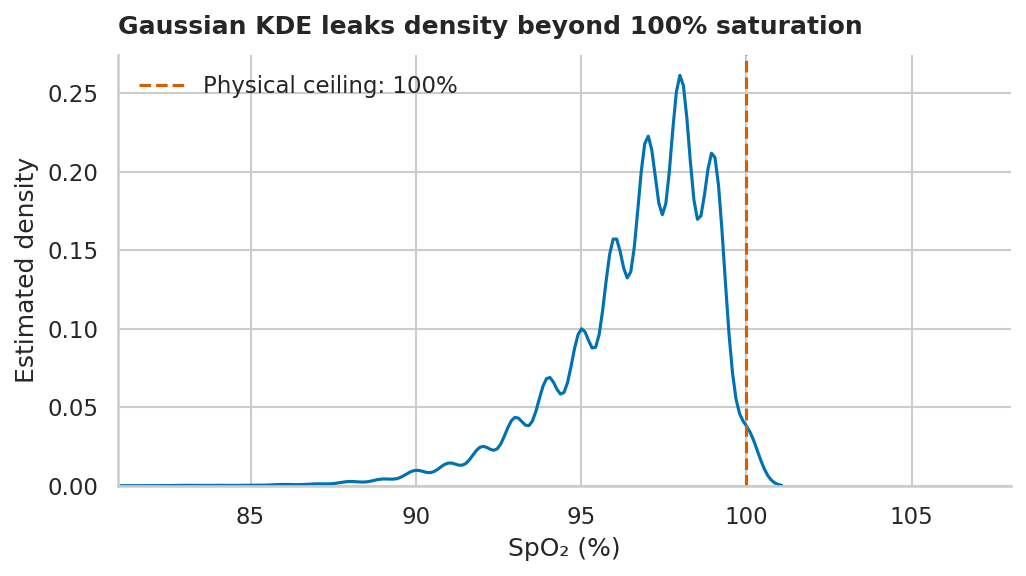

Observed maximum SpO₂: 100 | rows above 100%: 0


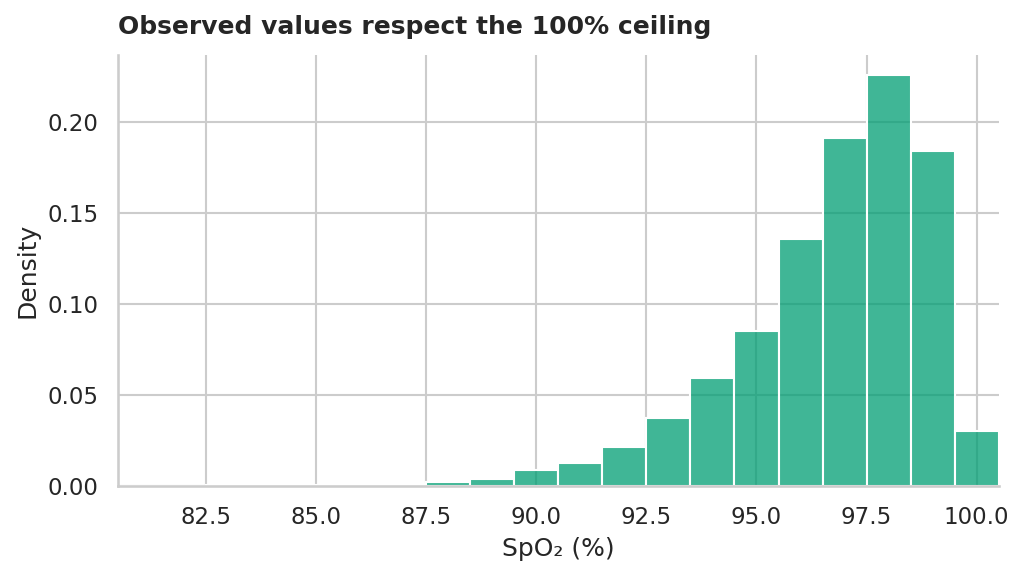

Diagnosis: kernel smoothing spreads mass beyond a bounded variable's support. The density beyond 100% is a KDE boundary artifact, not observed patients.


In [ ]:
# A9. KDE beyond the physical ceiling of SpO2
spo2 = vitals_raw.spo2.dropna()
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(x=spo2, bw_method="scott", cut=3, ax=ax, color=PALETTE["series"][0])
ax.set_xlim(spo2.min(), 108)
ax.axvline(100, color=PALETTE["series"][1], linestyle="--", label="Physical ceiling: 100%")
ax.set_xlabel("SpO₂ (%)"); ax.set_ylabel("Estimated density")
ax.set_title("Gaussian KDE leaks density beyond 100% saturation")
ax.legend(); fig.tight_layout(); plt.show()
print("Observed maximum SpO₂:", spo2.max(), "| rows above 100%:", int((spo2 > 100).sum()))
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(spo2, discrete=True, stat="density", ax=ax, color=PALETTE["series"][2])
ax.set_xlim(spo2.min()-.5, 100.5)
ax.set_xlabel("SpO₂ (%)"); ax.set_ylabel("Density")
ax.set_title("Observed values respect the 100% ceiling")
fig.tight_layout(); plt.show()
print("Diagnosis: kernel smoothing spreads mass beyond a bounded variable's support. The density beyond 100% is a KDE boundary artifact, not observed patients.")

## Part B — Lie Factor audit
The formula assumes that the visual encoding is a comparable scalar effect relative to a meaningful baseline. For Chart F (dual axes), there is no single common ink ratio: the two independent axis limits can be changed arbitrarily, so a single Lie Factor is not well-defined.

In [ ]:
lf_data = pd.read_csv(DATA / "case07_lie_factor.csv")
lie_rows = []
for _, row in lf_data.iterrows():
    lf, de, ge = lie_factor(row.value_start, row.value_end, row.ink_start, row.ink_end,
                            ink_dimension=int(row.ink_dimension))
    lie_rows.append({"chart": row.chart_id, "subject": row.subject, "data_effect": de,
                     "graphic_effect": ge, "lie_factor": lf, "verdict": lie_verdict(lf),
                     "dimension": int(row.ink_dimension), "encoding": row.how_the_graphic_encodes_it})
lie_table = pd.DataFrame(lie_rows).set_index("chart")
display(lie_table.round(3))
print("Honest chart:", lie_table.index[lie_table.verdict.eq("honest")].tolist())
print("Charts requiring area-aware ink_dimension=2:", lie_table.index[lie_table.dimension.eq(2)].tolist())
print("Chart F: no single Lie Factor can be computed because independent y-axis ranges create no common visual scale. Actual revenue-cost difference:")
display(dual.assign(profit=dual.revenue_pkr_m-dual.cost_pkr_m))

,subject,data_effect,graphic_effect,lie_factor,verdict,dimension,encoding
chart,,,,,,,
A,Corporate tax rate,0.067,5.000,75.00,exaggerates 75.00x,1,"Bars drawn from a 29.6% baseline, so only the ..."
B,Federal health budget (Rs bn),0.500,1.250,2.50,exaggerates 2.50x,2,A coin icon scaled 1.5x in BOTH height and width
C,Export earnings ($ bn),0.200,0.200,1.00,honest,1,Bars from zero: 5.0 cm then 6.0 cm
D,Air-pollution index,0.500,0.125,0.25,understates (0.25),1,Bars drawn 8.0 cm then 9.0 cm tall
E,City population (millions),3.000,15.000,5.00,exaggerates 5.00x,2,A bubble whose RADIUS was set proportional to ...


Honest chart: ['C']
Charts requiring area-aware ink_dimension=2: ['B', 'E']
Chart F: no single Lie Factor can be computed because independent y-axis ranges create no common visual scale. Actual revenue-cost difference:


,month,revenue_pkr_m,cost_pkr_m,profit
0,Jan,52,44,8
1,Feb,58,46,12
2,Mar,61,47,14
3,Apr,66,49,17
4,May,71,51,20
5,Jun,78,53,25


**Interpretation.** A uses a baseline close to the data values, magnifying the visible bar-tip change. B scales a coin in both height and width; its visible area grows with the square of the linear scale. C is drawn from zero and has proportional length. D's ink length grows less than the data effect, understating the increase. E sets bubble radius proportional to the value, so area scales with the square of the value and exaggerates the change. An understated chart still distorts the evidence and can benefit whoever wants the change to appear smaller; the data alone cannot establish the publisher's motive.

## Part C : Colour-vision-deficiency palette audit

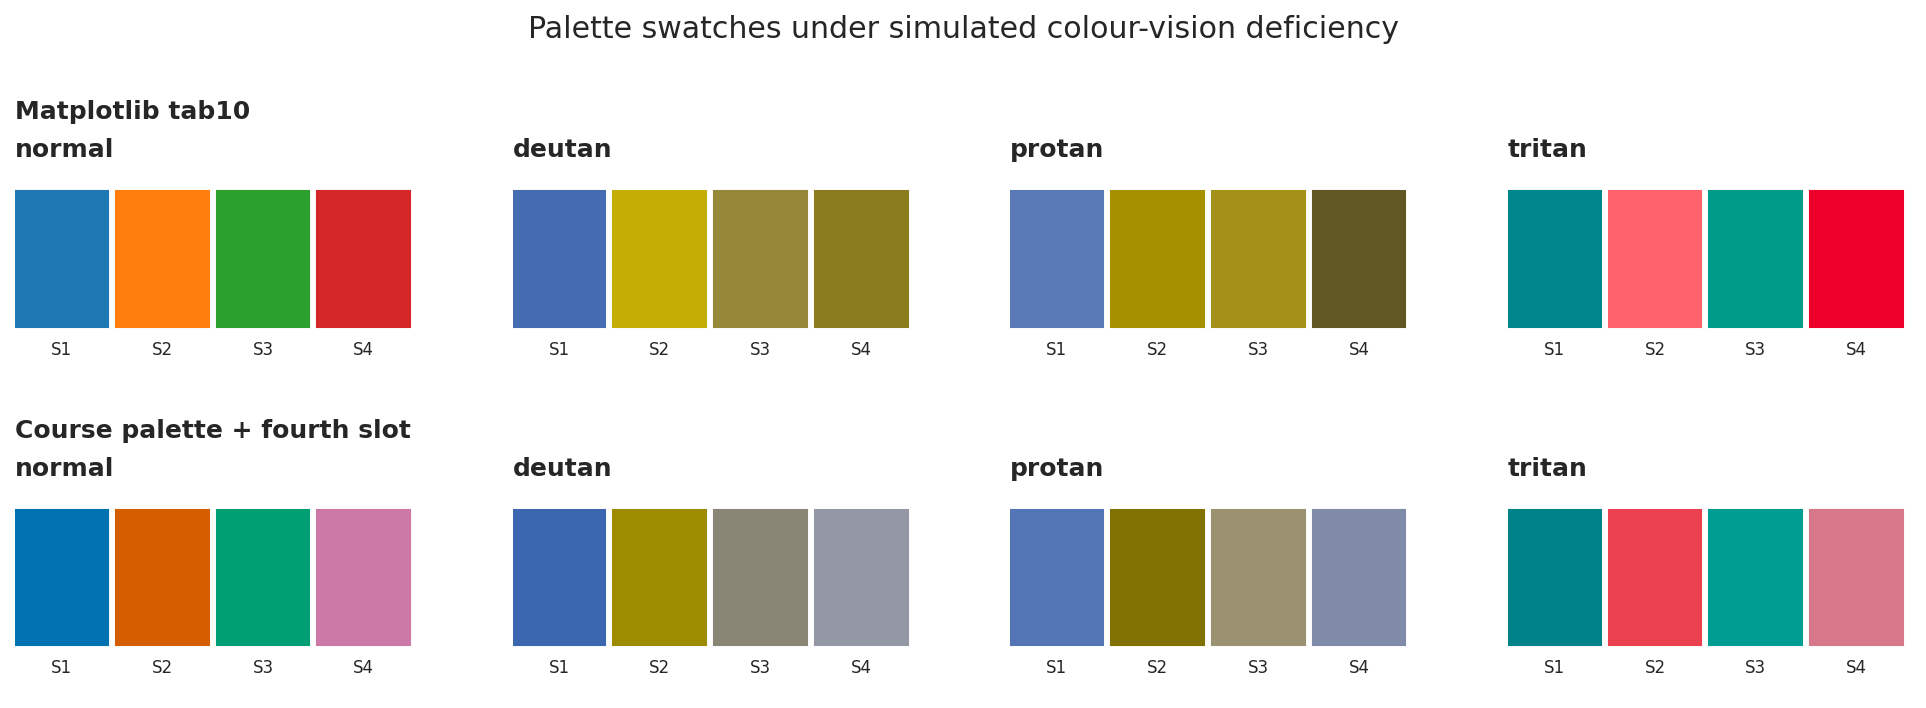

,palette,vision,pair,colour_1,colour_2,delta_E_OKLab_x100,verdict
0,Matplotlib tab10,normal,S2 / S4,#FF7F0E,#D62728,18.6,clear
1,Matplotlib tab10,deutan,S3 / S4,#2CA02C,#D62728,4.1,FAILS — same colour
2,Matplotlib tab10,protan,S2 / S3,#FF7F0E,#2CA02C,0.7,FAILS — same colour
3,Matplotlib tab10,tritan,S1 / S3,#1F77B4,#2CA02C,6.7,needs a second channel
4,Course palette,normal,S2 / S4,#D55E00,#CC79A7,16.4,clear
5,Course palette,deutan,S3 / S4,#009E73,#CC79A7,7.5,needs a second channel
6,Course palette,protan,S1 / S4,#0072B2,#CC79A7,9.5,ok
7,Course palette,tritan,S1 / S3,#0072B2,#009E73,8.4,ok


Rule: use no more than three hue-only categories. If more categories are required, add redundant channels (marker shape, direct labels, line style, texture, or small multiples); do not rely on a fourth colour alone.


In [ ]:
MY_PALETTE = ["#1F77B4", "#FF7F0E", "#2CA02C", "#D62728"]  # Matplotlib tab10 first four
COURSE_PALETTE = PALETTE["series"] + [PALETTE["series_4th"]]
KINDS = ["normal", "deutan", "protan", "tritan"]

fig, axes = plt.subplots(2, 4, figsize=(13, 4.8))
for row_i, (palette, label) in enumerate([(MY_PALETTE, "Matplotlib tab10"), (COURSE_PALETTE, "Course palette + fourth slot")]):
    for col_i, kind in enumerate(KINDS):
        ax = axes[row_i, col_i]
        shown = palette if kind == "normal" else simulate_cvd(palette, kind)
        for i, color in enumerate(shown):
            ax.add_patch(plt.Rectangle((i, 0), .92, 1, color=color))
            ax.text(i+.46, -.2, f"S{i+1}", ha="center", fontsize=8)
        ax.set_xlim(0, len(palette)); ax.set_ylim(-.35, 1.1); ax.axis("off")
        ax.set_title(kind)
    axes[row_i, 0].text(0, 1.3, label, transform=axes[row_i,0].transAxes, weight="bold")
fig.suptitle("Palette swatches under simulated colour-vision deficiency")
fig.tight_layout(); plt.show()

def palette_audit(palette, label):
    rows=[]
    for kind in ["normal", "deutan", "protan", "tritan"]:
        i,j,a,b,dist = worst_pair(palette, kind)
        rows.append({"palette":label,"vision":kind,"pair":f"S{i} / S{j}","colour_1":a,"colour_2":b,
                     "delta_E_OKLab_x100":dist,"verdict":verdict(dist)})
    return rows
audit_df = pd.DataFrame(palette_audit(MY_PALETTE,"Matplotlib tab10") +
                        palette_audit(COURSE_PALETTE,"Course palette"))
display(audit_df.round({"delta_E_OKLab_x100":1}))
print("Rule: use no more than three hue-only categories. If more categories are required, add redundant channels (marker shape, direct labels, line style, texture, or small multiples); do not rely on a fourth colour alone.")

## Part D — Clinical review figure (cleaning audit and 2×2 figure)
The four initial inspection clues are inconsistent ward spellings, three date formats, impossible BMI sentinels, and physiologically impossible heart-rate readings. The risk-score column is a ratio and MAP is derived; both require special handling in interpretation.

In [ ]:
# Initial inspection required by the brief
v = pd.read_csv(DATA / "vitals_10k.csv")
v.info()
display(v.describe().T)
display(v.ward.value_counts())
display(v.admit_date.head(20).tolist())
display(v[["heart_rate","bmi","spo2","los_days"]].agg(["min","max"]).T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  object 
 1   admit_date      10000 non-null  object 
 2   ward            10000 non-null  object 
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  object 
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), object(4)
memory usage: 1.2+ MB


,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65


ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

['2026-01-19',
 '08-Mar-2026',
 '2026-02-26',
 '27/02/2026',
 '09/01/2026',
 '01-Apr-2026',
 '17-Apr-2026',
 '24-Mar-2026',
 '14-Apr-2026',
 '02-Jan-2026',
 '10/03/2026',
 '10/02/2026',
 '12-Apr-2026',
 '29/03/2026',
 '17-Apr-2026',
 '12/02/2026',
 '2026-03-28',
 '2026-02-03',
 '11-Apr-2026',
 '08/01/2026']

,min,max
heart_rate,0.0,415.00
bmi,0.0,999.00
spo2,81.0,100.00
los_days,0.0,273.65


In [ ]:
# Cleaning with an explicit audit trail
clean = v.copy()
audit_log = []
audit_log.append({"step":"Rows loaded","rule":"No exclusion; source rows", "n_removed":0, "before":len(clean), "after":len(clean), "detail":"Synthetic source file"})
ward_map = {
    "general medicine":"General Medicine", "gen medicine":"General Medicine",
    "cardiology":"Cardiology", "cardio":"Cardiology",
    "day surgery":"Day Surgery", "day-surgery":"Day Surgery",
    "intensive care":"Intensive Care", "icu":"Intensive Care", "i.c.u":"Intensive Care"
}
clean["ward_clean"] = clean["ward"].astype(str).str.strip().str.lower().map(ward_map)
audit_log.append({"step":"Ward labels conformed","rule":"Normalize case/whitespace and map known aliases; no rows removed", "n_removed":0, "before":len(clean), "after":len(clean), "detail":f"{clean.ward_clean.nunique()} canonical wards; unmapped={clean.ward_clean.isna().sum()}"})

# Explicit parsing by the three formats found in the raw strings.
date_s = clean["admit_date"].astype(str)
parsed = pd.to_datetime(date_s, format="%Y-%m-%d", errors="coerce")
for fmt in ["%d-%b-%Y", "%d/%m/%Y"]:
    parsed = parsed.fillna(pd.to_datetime(date_s, format=fmt, errors="coerce"))
clean["admit_dt"] = parsed
bad_dates = int(clean.admit_dt.isna().sum())
audit_log.append({"step":"Admission dates parsed","rule":"Parse YYYY-MM-DD, DD-Mon-YYYY, DD/MM/YYYY explicitly; invalid dates remain missing", "n_removed":0, "before":len(clean), "after":len(clean), "detail":f"unparsed dates={bad_dates}"})

bmi_before = clean.bmi.mean()
bmi_bad = clean.bmi >= 100  # 999 is sentinel; threshold isolates impossible values
bmi_n = int(bmi_bad.sum())
clean.loc[bmi_bad, "bmi"] = np.nan
bmi_after = clean.bmi.mean()
audit_log.append({"step":"BMI sentinels","rule":"BMI >= 100 treated as sentinel/missing, not a plausible BMI", "n_removed":bmi_n, "before":len(clean), "after":len(clean), "detail":f"mean {bmi_before:.2f} -> {bmi_after:.2f}; values set missing, rows retained"})

hr_before = clean.heart_rate.mean()
hr_bad = (clean.heart_rate < 30) | (clean.heart_rate > 250)
hr_n = int(hr_bad.sum())
clean.loc[hr_bad, "heart_rate"] = np.nan
hr_after = clean.heart_rate.mean()
audit_log.append({"step":"Heart-rate device faults","rule":"Readings <30 or >250 bpm treated as device faults; set missing, retain rows", "n_removed":hr_n, "before":len(clean), "after":len(clean), "detail":f"mean {hr_before:.2f} -> {hr_after:.2f} bpm"})

# MAP is arithmetic derivation from systolic and diastolic; exclude it from inferential correlation heatmap.
audit_log.append({"step":"Derived MAP excluded from heatmap","rule":"Exclude map_mmhg because it is computed from systolic/diastolic; no rows removed", "n_removed":0, "before":len(clean), "after":len(clean), "detail":"Avoid treating arithmetic correlation as an independent discovery"})
display(pd.DataFrame(audit_log))

,step,rule,n_removed,before,after,detail
0,Rows loaded,No exclusion; source rows,0,10000,10000,Synthetic source file
1,Ward labels conformed,Normalize case/whitespace and map known aliase...,0,10000,10000,4 canonical wards; unmapped=0
2,Admission dates parsed,"Parse YYYY-MM-DD, DD-Mon-YYYY, DD/MM/YYYY expl...",0,10000,10000,unparsed dates=0
3,BMI sentinels,"BMI >= 100 treated as sentinel/missing, not a ...",402,10000,10000,"mean 66.18 -> 27.11; values set missing, rows ..."
4,Heart-rate device faults,Readings <30 or >250 bpm treated as device fau...,37,10000,10000,mean 78.83 -> 78.05 bpm
5,Derived MAP excluded from heatmap,Exclude map_mmhg because it is computed from s...,0,10000,10000,Avoid treating arithmetic correlation as an in...


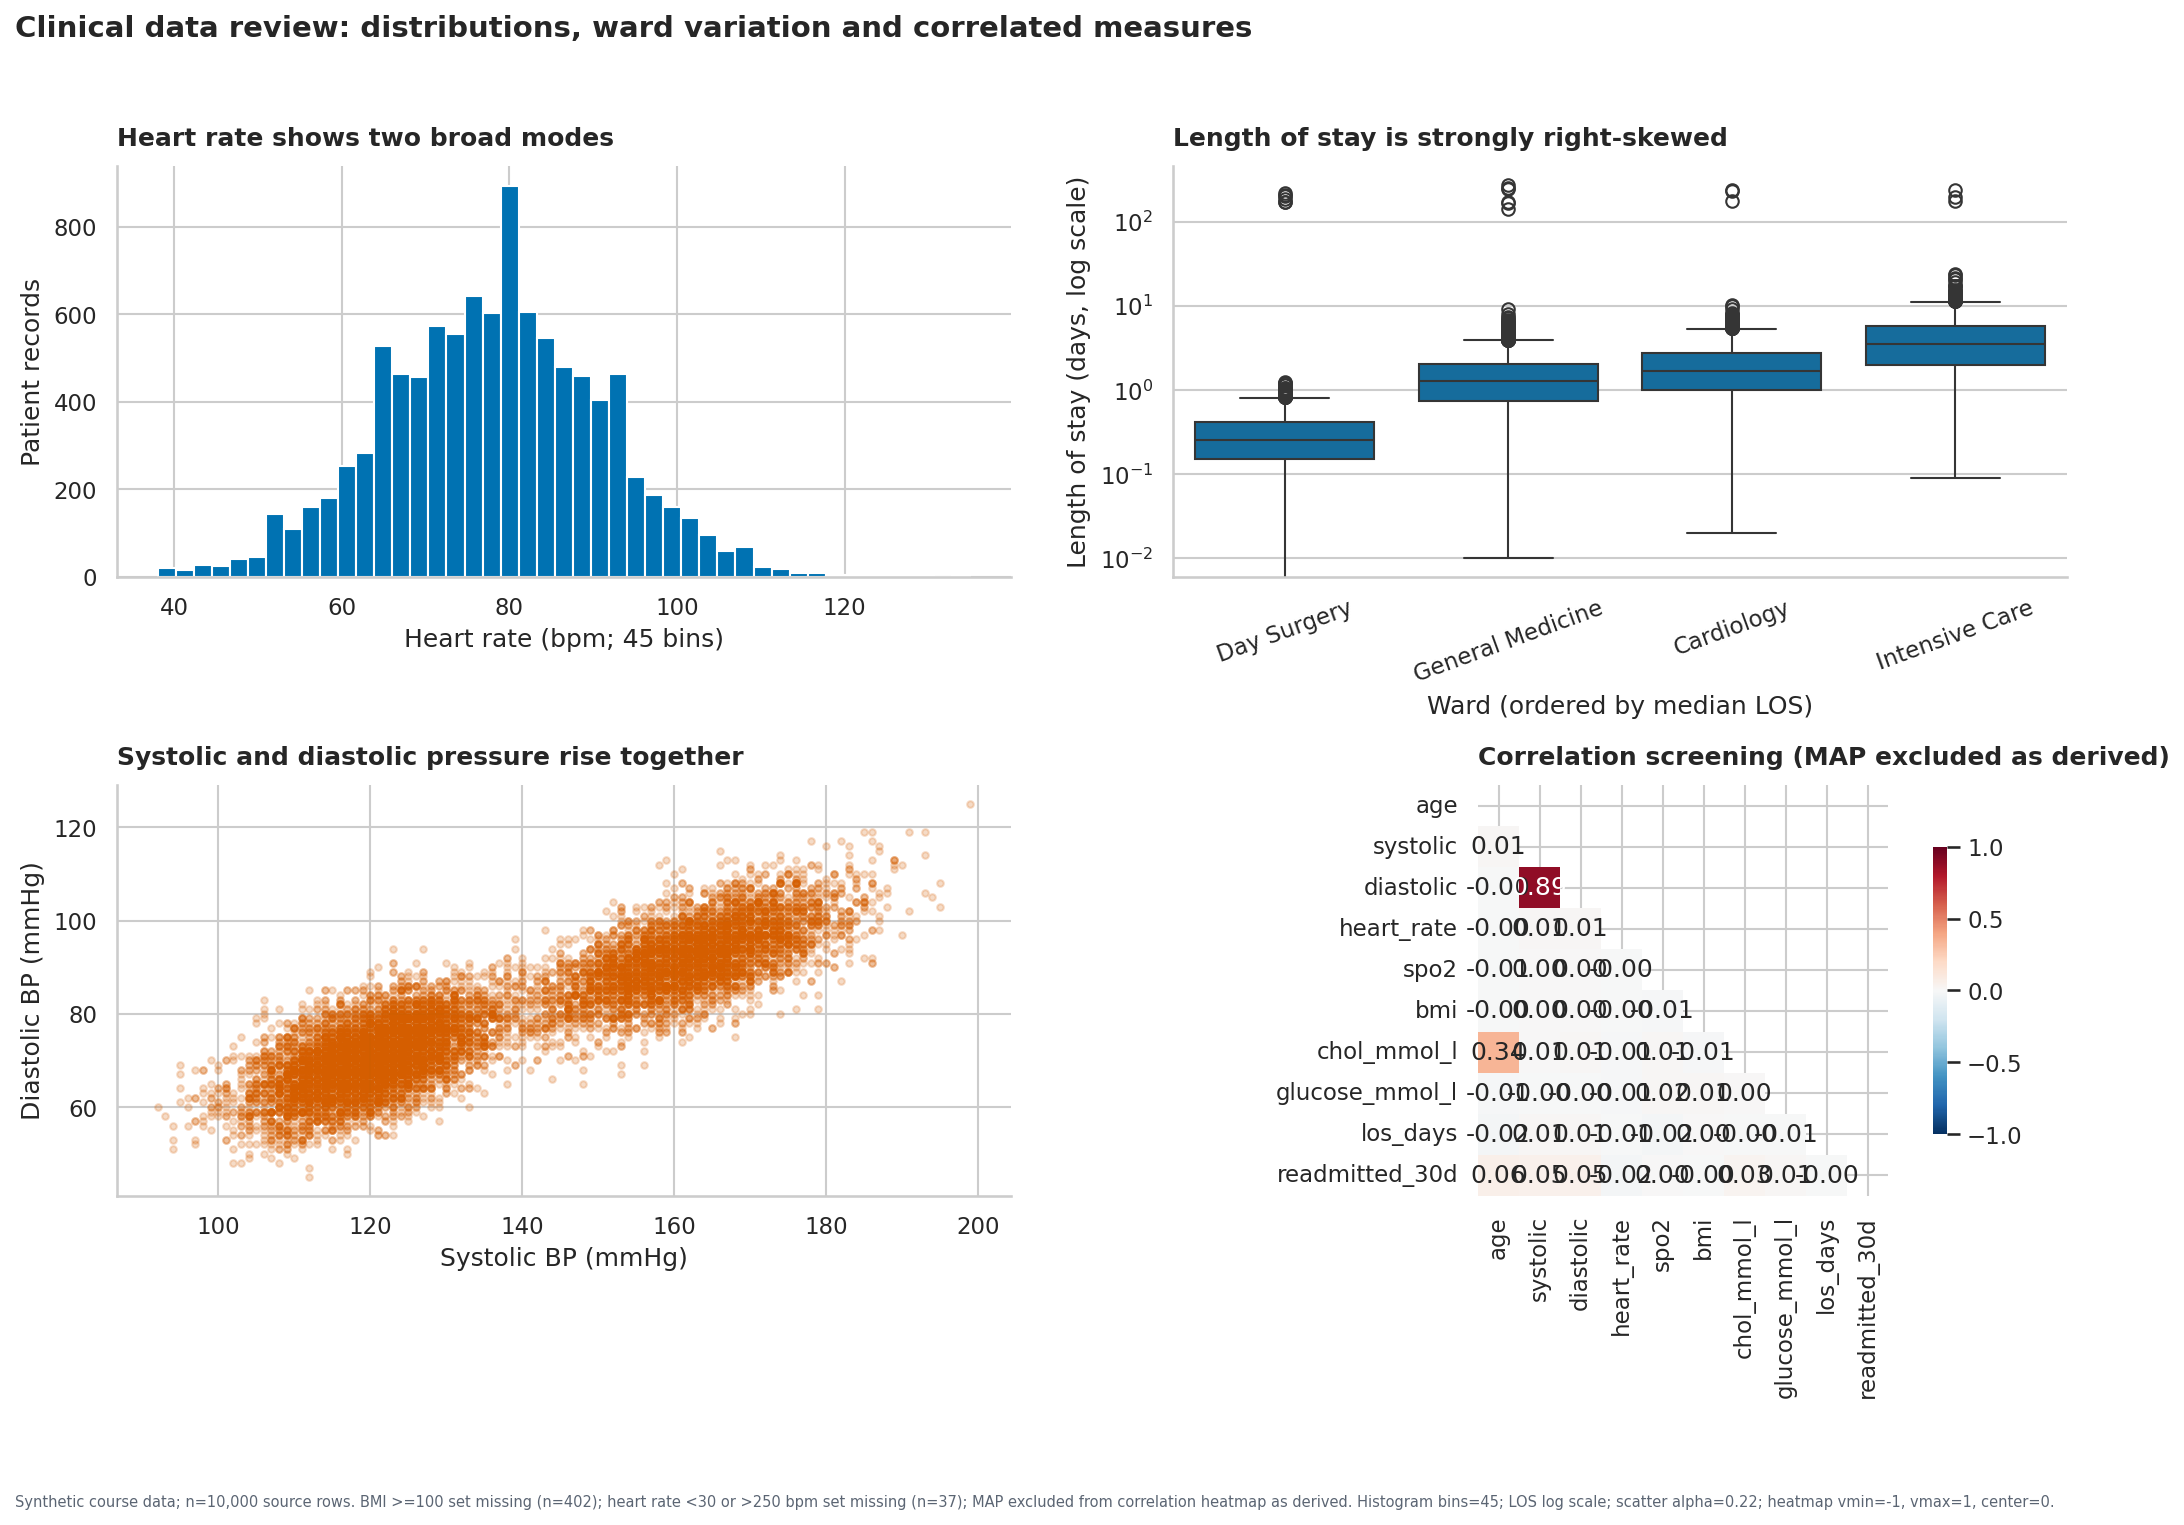

Saved: /mnt/data/data-visualization-main/week3/assignments/partD_figure.png


In [ ]:
# Select one useful scatter from the heatmap after excluding derived MAP.
# The heatmap includes numeric clinical measurements; categorical/ID/rate columns are excluded.
heat_cols = ["age","systolic","diastolic","heart_rate","spo2","bmi","chol_mmol_l","glucose_mmol_l","los_days","readmitted_30d"]
heat = clean[heat_cols].corr()
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# Panel 1: bimodal heart rate distribution; declare binning
hr_values = clean.heart_rate.dropna()
axes[0,0].hist(hr_values, bins=45, color=PALETTE["series"][0], edgecolor="white")
axes[0,0].set_title("Heart rate shows two broad modes")
axes[0,0].set_xlabel("Heart rate (bpm; 45 bins)")
axes[0,0].set_ylabel("Patient records")

# Panel 2: LOS across wards; log axis makes the right-skew visible without hiding outliers
ward_order = clean.groupby("ward_clean").los_days.median().sort_values().index
sns.boxplot(data=clean, x="ward_clean", y="los_days", order=ward_order,
            color=PALETTE["series"][0], showfliers=True, ax=axes[0,1])
axes[0,1].set_yscale("log")
axes[0,1].set_title("Length of stay is strongly right-skewed")
axes[0,1].set_xlabel("Ward (ordered by median LOS)")
axes[0,1].set_ylabel("Length of stay (days, log scale)")
axes[0,1].tick_params(axis="x", rotation=20)

# Panel 3: choose systolic vs diastolic BP, clinically coherent; jitter-free alpha handles overplotting
plot_df = clean[["systolic","diastolic"]].dropna()
axes[1,0].scatter(plot_df.systolic, plot_df.diastolic, s=10, alpha=.22, color=PALETTE["series"][1])
axes[1,0].set_title("Systolic and diastolic pressure rise together")
axes[1,0].set_xlabel("Systolic BP (mmHg)")
axes[1,0].set_ylabel("Diastolic BP (mmHg)")

# Panel 4: signed correlation scale, upper triangle masked, no derived MAP
mask = np.triu(np.ones_like(heat, dtype=bool))
sns.heatmap(heat, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, cbar_kws={"shrink":.7}, ax=axes[1,1])
axes[1,1].set_title("Correlation screening (MAP excluded as derived)")
fig.suptitle("Clinical data review: distributions, ward variation and correlated measures", x=.01, ha="left", fontsize=14, weight="bold")
for a in axes.flat:
    a.spines["top"].set_visible(False); a.spines["right"].set_visible(False)
note = (f"Synthetic course data; n=10,000 source rows. BMI >=100 set missing (n={bmi_n}); "
        f"heart rate <30 or >250 bpm set missing (n={hr_n}); MAP excluded from correlation heatmap as derived. "
        "Histogram bins=45; LOS log scale; scatter alpha=0.22; heatmap vmin=-1, vmax=1, center=0.")
fig.text(.01, -.015, note, fontsize=7, color=PALETTE["ink_soft"], ha="left")
fig.tight_layout(rect=[0, .04, 1, .96])
fig.savefig(OUT / "partD_figure.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", OUT / "partD_figure.png")

## Part E Written justification (one-page draft)

**Panel 1  heart-rate distribution.** The histogram answers whether monitor readings have a plausible distribution and reveals broad modes and anomalies. A histogram is appropriate for one continuous variable; 45 bins are stated explicitly to avoid disguising the shape with arbitrary binning.

**Panel 2 length of stay by ward.** The box plot compares medians, spread and outliers across the four canonical wards. Wards are ordered by median LOS, and the logarithmic y-axis makes the long right tail readable without suppressing fliers. All plotted observations remain visible.

**Panel 3  systolic versus diastolic blood pressure.** The scatter checks the relationship between two clinically related measurements. Small points with alpha = 0.22 reduce overplotting; both axes use mmHg and a common coordinate system.

**Panel 4  correlation screening.** The lower-triangle heatmap summarizes pairwise Pearson correlations. A diverging palette with `vmin=-1`, `vmax=1`, and `center=0` preserves sign and comparability; annotations show coefficients. `map_mmhg` is excluded because it is calculated from systolic and diastolic pressure, so its correlation is partly built into the formula. Correlations are exploratory and do not establish causation.

**Cleaning and exclusions.** The source contains 10,000 rows. Ward aliases were normalized into four labels; no rows were removed. Admission dates were parsed using three explicit formats; invalid values, if any, remain missing rather than being guessed. BMI values ≥100 were treated as sentinels and set to missing, with the number and mean shift recorded in the audit table. Heart-rate readings below 30 or above 250 bpm were treated as device faults and set to missing, not silently hidden; the audit table reports the count and mean before/after. Rows were retained, and the original data remain available in `v`. MAP was excluded only from the correlation heatmap, not from the dataset. These rules are based on plausibility and measurement provenance, not on whether they strengthen a result.

**Reproducibility and limitations.** All datasets are synthetic course data. The figure is saved at 300 dpi before display. The choices of 45 bins, log scale, alpha, heatmap range and triangle mask are explicit. The correlations are descriptive, and the synthetic patterns should not be interpreted as clinical evidence.